This is a tutorial to get comfortable with the concepts of MMMs and PyMC. THe idea os these series of notebooks is to add complexity with each interaction

## Simple MMM
This is a simple MMM

We generate a simple MMM with:
- Two independent spend (no collinearity)
- Basically we are modelling two random variables and should be straight forward

In [12]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(0)
n = 104  # 2 years of weekly data

# Two channels with independent spend (no collinearity)
tv = rng.uniform(0, 100, n)
social = rng.uniform(0, 50, n)

# True effects
BASE = 1000
BETA_TV = 3.0       # each 1 € on TV -> 3 sales
BETA_SOCIAL = 5.0   # each 1 € on social -> 5 sales
NOISE = 50

sales = BASE + BETA_TV * tv + BETA_SOCIAL * social + rng.normal(0, NOISE, n)

df = pd.DataFrame({"tv": tv.round(1), "social": social.round(1), "sales": sales.round(0)})

In [3]:
df.head()

,tv,social,sales
0,63.7,13.3,1234.0
1,27.0,26.9,1224.0
2,4.1,22.1,1058.0
3,1.7,46.6,1214.0
4,81.3,2.0,1323.0


In [2]:
# Given that the two channels are independent, we should be able to run this straight forward with an OLS. However, we will also run it with PyMC to compare results.


In [13]:
import statsmodels.formula.api as smf

ols_model = smf.ols(formula="sales ~ tv + social", data=df).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.837
Model:                            OLS   Adj. R-squared:                  0.834
Method:                 Least Squares   F-statistic:                     259.6
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           1.57e-40
Time:                        13:51:42   Log-Likelihood:                -568.60
No. Observations:                 104   AIC:                             1143.
Df Residuals:                     101   BIC:                             1151.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    991.6875     14.240     69.643      0.0

Pretty straight forward --> p-values are statistically significant, and the betas are correct!

## Bayesian Model:

So, with the following model we use the pymc library.
- We input relaxed priors
- We scale the variables as a good practice for better models to come
- We do a prior predictive check before fitting the data
- We sample the posterior distributions and re-scale the values to compare them

In [26]:
from pymc.distributions.continuous import Beta
#PyMC model

import pymc as pm
import pytensor.tensor as pt

channels = ['tv', 'social']

X = df[channels].values
y = df['sales'].values


X = X / X.max(axis=0)          # each channel between 0 and 1
y_scale = y.max()
y = y / y_scale                # sales between 0 and 1


with pm.Model() as model:

    intercept = pm.Normal("intercept", 0.5, 0.25)

    media = 0
    for i, ch in enumerate(channels):
      beta = pm.HalfNormal(f"beta_{ch}", 0.7)
      contrib = beta * X[:, i]
      media += contrib

    # Matrix multiplication with numeric control values

    mu = intercept + media
    sigma = pm.HalfNormal("sigma", 0.1)
    pm.Normal("y", mu=mu, sigma=sigma, observed=y)


    prior = pm.sample_prior_predictive()
    idata = pm.sample()



Output()

## Prior predictive check:
In a nutshell, it simulates the sales the model would produce from the priors alone, **before seeing any data.**
-If priors are too relaxed, the model might not learn much,
-If priors are very strong, they will bias the end result (for good or for bad)
-If the model does not learn much from the data, the output will be similar to the priors.

<Axes: xlabel='y'>

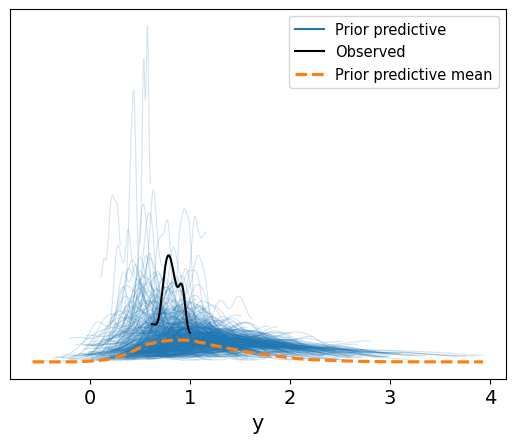

In [27]:
az.plot_ppc(prior, group="prior", observed=True)

In [28]:
post = idata.posterior
x_max = df[channels].max().values


print("intercept:", (post["intercept"] * y_scale).mean().item())
print("sigma:", (post["sigma"] * y_scale).mean().item())
for i, ch in enumerate(channels):
    print(ch, (post[f"beta_{ch}"] * y_scale / x_max[i]).mean().item())

intercept: 991.0516689699632
sigma: 58.85736195065884
tv 2.9902856699203832
social 5.106412078644


In [31]:

import arviz as az
import xarray as xr

real = xr.Dataset({
    "intercept": post["intercept"] * y_scale,
    "sigma": post["sigma"] * y_scale,
    **{f"beta_{ch}": post[f"beta_{ch}"] * y_scale / x_max[i] for i, ch in enumerate(channels)},
})

az.summary(real)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intercept,991.052,14.411,964.694,1019.107,0.472,0.388,947.0,884.0,1.0
sigma,58.857,4.174,51.726,66.941,0.111,0.111,1428.0,1148.0,1.0
beta_tv,2.990,0.187,2.639,3.350,0.005,0.005,1214.0,1131.0,1.0
beta_social,5.106,0.397,4.370,5.839,0.013,0.010,1013.0,1007.0,1.0
